<a href="https://colab.research.google.com/github/Satyam593-lang/abs/blob/main/Marketing%20analyst%20assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Marketing Analytics Assignment2
BHARGO JAISWAL
0251MBA057

In [18]:
# SETUP & DATA LOADING
import pandas as pd
import numpy as np
from datetime import datetime
from scipy import stats
import math


# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Upload the Assignment2_Dataset.xlsx to Colab first!
file_path = '/content/Assignment2_Dataset.xlsx'

# Load the transaction sheet
df_txn = pd.read_excel(file_path, sheet_name='S1_Customer_Transactions')
df_reviews = pd.read_excel(file_path, sheet_name='S2_Product_Reviews')

# Convert dates to datetime objects
df_txn['Transaction_Date'] = pd.to_datetime(df_txn['Transaction_Date'])
df_reviews['Review_Date'] = pd.to_datetime(df_reviews['Review_Date'])

# Define the analysis date
analysis_date = pd.to_datetime('2026-08-01')

print("Data loaded successfully!")
print(f"Total Transactions: {len(df_txn)}")
print(f"Total Reviews: {len(df_reviews)}")

Data loaded successfully!
Total Transactions: 2410
Total Reviews: 150


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
print("visualization libraries loaded")

visualization libraries loaded


In [17]:
# Q1 - RFM ANALYSIS

# 1. Calculate Raw RFM
rfm = df_txn.groupby('Customer_ID').agg({
    'Transaction_Date': lambda x: (analysis_date - x.max()).days, # Recency
    'Txn_ID': 'nunique',                                          # Frequency
    'Amount_INR': 'sum'                                           # Monetary
})
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# 2. Assign Quintile Scores (1-5)
# Note: For Recency, lower is better, so we use ascending=False for the ranking
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# 3. Define Segments (Adjust logic based on your course's exact definitions if needed)
def assign_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Regulars'
    elif r >= 4 and f <= 2:
        return 'New/Promising'
    elif r <= 2 and f >= 3: # Was loyal, but hasn't purchased in a while
        return 'At-Risk-was-loyal'
    else:
        return 'Hibernating'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

# 4. Build Segment Table
# Reset index to bring 'Customer_ID' back as a column for count aggregation
rfm_reset = rfm.reset_index()
total_revenue = rfm_reset['Monetary'].sum()
segment_table = rfm_reset.groupby('Segment').agg({
    'Customer_ID': 'count',
    'Monetary': ['mean', 'sum']
})
segment_table.columns = ['Customer_Count', 'Avg_Spend', 'Total_Revenue']
segment_table['Revenue_Share_%'] = (segment_table['Total_Revenue'] / total_revenue) * 100

print("--- Q1: RFM Segment Table ---")
print(segment_table.round(2))

--- Q1: RFM Segment Table ---
                   Customer_Count  Avg_Spend  Total_Revenue  Revenue_Share_%
Segment                                                                     
At-Risk-was-loyal              73    8138.47         594108            17.95
Champions                      98   19882.88        1948522            58.86
Hibernating                   127    2116.00         268732             8.12
New/Promising                  33    1777.27          58650             1.77
Regulars                       69    6385.59         440606            13.31


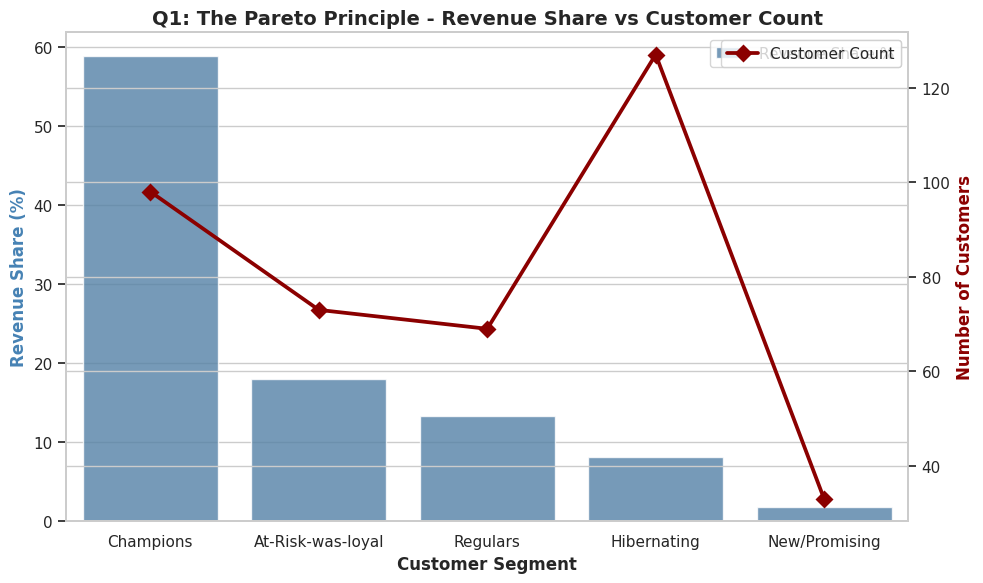

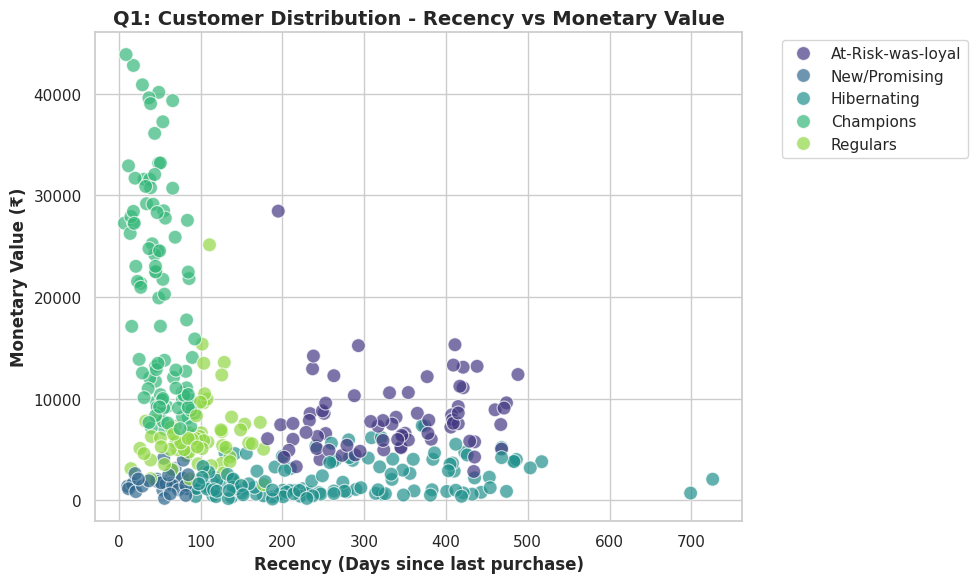

In [19]:
# Q1 VISUALS - CUSTOMER SEGMENTS

# 1. Bar Chart: Revenue Share vs Customer Count by Segment
fig, ax1 = plt.subplots(figsize=(10, 6))

# Sort by Revenue Share for better visualization
segment_table_sorted = segment_table.sort_values('Revenue_Share_%', ascending=False)

# Plot Revenue Share
sns.barplot(x=segment_table_sorted.index, y='Revenue_Share_%', data=segment_table_sorted,
            ax=ax1, color='steelblue', alpha=0.8, label='Revenue Share %')

# Add Customer Count on a secondary axis
ax2 = ax1.twinx()
sns.pointplot(x=segment_table_sorted.index, y='Customer_Count', data=segment_table_sorted,
              ax=ax2, color='darkred', markers='D', label='Customer Count')

ax1.set_title('Q1: The Pareto Principle - Revenue Share vs Customer Count', fontsize=14, fontweight='bold')
ax1.set_ylabel('Revenue Share (%)', color='steelblue', fontweight='bold')
ax2.set_ylabel('Number of Customers', color='darkred', fontweight='bold')
ax1.set_xlabel('Customer Segment', fontweight='bold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('Q1_Segment_Performance.png', dpi=300) # Saves for your report
plt.show()

# 2. Scatter Plot: Recency vs Monetary (colored by Segment)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm, x='Recency', y='Monetary', hue='Segment',
                palette='viridis', s=100, alpha=0.7)
plt.title('Q1: Customer Distribution - Recency vs Monetary Value', fontsize=14, fontweight='bold')
plt.xlabel('Recency (Days since last purchase)', fontweight='bold')
plt.ylabel('Monetary Value (₹)', fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('Q1_Scatter_Recency_Monetary.png', dpi=300)
plt.show()

CLV & BREAK EVEN

In [14]:
# Note: The PDF formula has a typo. The standard CLV formula is (m * r) / (1 + i - r).
# m = margin, r = retention, i = discount rate (1.5% = 0.015)
i = 0.015

# Given Data
champions_m, champions_r = 560, 0.96
regulars_m, regulars_r = 310, 0.92
at_risk_m, at_risk_r = 420, 0.88

def calc_clv(m, r, i):
    return (m * r) / (1 + i - r)

clv_champions = calc_clv(champions_m, champions_r, i)
clv_regulars = calc_clv(regulars_m, regulars_r, i)
clv_at_risk = calc_clv(at_risk_m, at_risk_r, i)

print(f"CLV Champions: ₹{clv_champions:.2f}")
print(f"CLV Regulars: ₹{clv_regulars:.2f}")
print(f"CLV At-Risk: ₹{clv_at_risk:.2f}")

# Break-even save rate for At-Risk
voucher_cost = 800
break_even_rate = voucher_cost / clv_at_risk

print(f"\nBreak-even Save Rate for ₹800 voucher: {break_even_rate*100:.2f}%")

CLV Champions: ₹9774.55
CLV Regulars: ₹3002.11
CLV At-Risk: ₹2737.78

Break-even Save Rate for ₹800 voucher: 29.22%


/tmp/ipykernel_1736/1130282519.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Segment', y='CLV (₹)', data=clv_data, palette=colors)


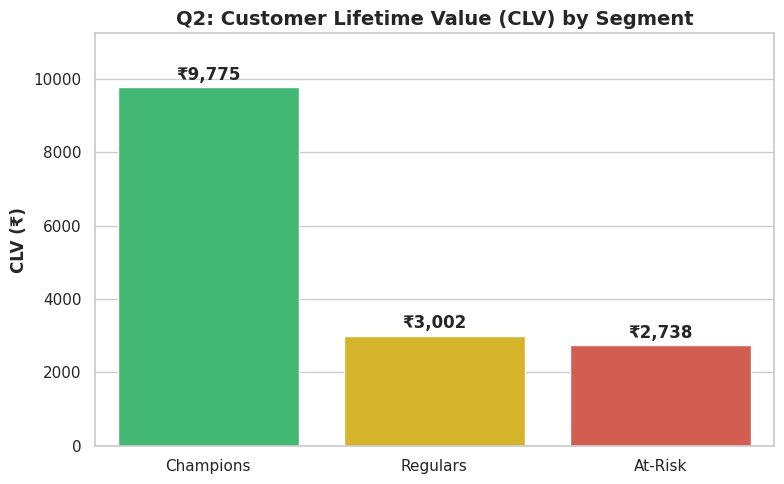

In [15]:


# Create a small dataframe for the plot
clv_data = pd.DataFrame({
    'Segment': ['Champions', 'Regulars', 'At-Risk'],
    'CLV (₹)': [clv_champions, clv_regulars, clv_at_risk]
})

plt.figure(figsize=(8, 5))
# Highlight the At-Risk segment since that's the focus of the voucher question
colors = ['#2ecc71', '#f1c40f', '#e74c3c']
ax = sns.barplot(x='Segment', y='CLV (₹)', data=clv_data, palette=colors)

# Add value labels on top of the bars
for p in ax.patches:
    ax.annotate(f'₹{p.get_height():,.0f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')

plt.title('Q2: Customer Lifetime Value (CLV) by Segment', fontsize=14, fontweight='bold')
plt.ylabel('CLV (₹)', fontweight='bold')
plt.xlabel('')
plt.ylim(0, max(clv_data['CLV (₹)']) * 1.15) # Add space for labels
plt.tight_layout()
plt.savefig('Q2_CLV_Comparison.png', dpi=300)
plt.show()

***A/B TEST***

In [20]:
#  Q3 - A/B TEST (TWO-PROPORTION Z-TEST)

# Experiment Data
n_A, conversions_A = 5000, 210
n_B, conversions_B = 5000, 271

p_A = conversions_A / n_A
p_B = conversions_B / n_B
uplift = (p_B - p_A) / p_A

# Pooled proportion for Z-test
p_pool = (conversions_A + conversions_B) / (n_A + n_B)
se_pool = math.sqrt(p_pool * (1 - p_pool) * (1/n_A + 1/n_B))

# Z-score
z_score = (p_B - p_A) / se_pool

# One-sided p-value
p_value = 1 - stats.norm.cdf(z_score)

# 95% Confidence Interval (Unpooled SE)
se_unpooled = math.sqrt((p_A * (1 - p_A) / n_A) + (p_B * (1 - p_B) / n_B))
margin_of_error = 1.96 * se_unpooled
ci_lower = (p_B - p_A) - margin_of_error
ci_upper = (p_B - p_A) + margin_of_error

print(f"Variant A Rate: {p_A*100:.2f}%")
print(f"Variant B Rate: {p_B*100:.2f}%")
print(f"Uplift: {uplift*100:.2f}%")
print(f"Z-score: {z_score:.3f}")
print(f"One-sided p-value: {p_value:.4f}")
print(f"95% CI on Difference: [{ci_lower:.4f}, {ci_upper:.4f}]")

if p_value < 0.05:
    print("Decision: Ship Variant B (Statistically Significant)")
else:
    print("Decision: Do Not Ship (Not Significant)")

Variant A Rate: 4.20%
Variant B Rate: 5.42%
Uplift: 29.05%
Z-score: 2.851
One-sided p-value: 0.0022
95% CI on Difference: [0.0038, 0.0206]
Decision: Ship Variant B (Statistically Significant)
